# 03 · Signatures — embryonic-development module scores & Gate 2

Score each cell for the three embryonic modules (**Gast** gastrulation, **pSom**
posterior somitogenesis, **Crest** neural crest) against the shared **union**
control pool, render them as deliverables, and evaluate **Gate 2**.

**Gate 2 — the two GO patterns, and why neither holds here.** A dataset passes
Gate 2 in one of two ways. *Branching* (Puram 2017): Gast and pSom form a
co-expression **hub** that diverges into distinct arms, with Crest a terminal
readout. *Non-branching* (Kürten 2021): Gast and pSom **co-vary** along one
trajectory body and Crest occupies the opposite terminal end. Peng's PDAC manifold
matches **neither**. Gast and pSom sit at **opposite poles and anti-correlate**
spatially (r = -0.41), there is **no co-expression hub** (joint-high fraction is
*below* the random expectation), and along the rooted axis Crest is **flat**, not
terminal. The anti-correlation is robust across every clustering scale (sub-region
sweep below). The embryonic developmental pattern is therefore **absent**:
**Gate 2 = NO-GO**, and with no bifurcation **Gate 3 = NA**. Per the task's
notebook-numbering rule a NO-GO at Gate 2 produces no correlation/modules
notebooks; the unconditional EMT-TF step follows as `04_expression`.
Deliverable: `signatures.h5ad`, `{Gast,pSom,Crest}_signature.pdf` + colorbars.

In [ ]:
import os, sys, glob
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
import scipy.sparse as sp
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)

### Load the rooted manifold (signatures already scored + smoothed in 02)

In [ ]:
adata = sc.read_h5ad(os.path.join(pth_out, 'manifold.h5ad'))
modules = {'Gast':'Gastrulation', 'pSom':'Somitogenesis', 'Crest':'Neural Crest'}
print('cells:', adata.shape[0], '| scores present:', [m for m in modules if m in adata.obs])
pth_feat = os.path.join(pth_data, 'features', 'biomart')
feat = {os.path.basename(f).replace('.csv',''): pd.read_csv(f).hsapiens.drop_duplicates()
        for f in sorted(glob.glob(os.path.join(pth_feat,'*.csv')))}
for src,lab in [('GSE162534','Gast'),('GSE229103','pSom'),('rRNAModifications','Crest')]:
    g = feat[src].loc[feat[src].isin(adata.var_names)]
    print(f'{lab}: {g.size}/{feat[src].size} genes present')

cells: 7945 | scores present: ['Gast', 'pSom', 'Crest']
Gast: 77/81 genes present
pSom: 90/98 genes present
Crest: 100/104 genes present


### Gate 2 test 1 — module geography (spatial correlations)
Both GO patterns require Gast and pSom to be *positively* associated (a shared
gradient, or a joint hub). Here they anti-correlate, and Crest anti-correlates with
both — three mutually exclusive territories, not a developmental axis.

In [ ]:
print('smoothed spatial correlations (geography):')
for a,b in [('Gast_sm','pSom_sm'),('Crest_sm','Gast_sm'),('Crest_sm','pSom_sm')]:
    r = np.corrcoef(adata.obs[a], adata.obs[b])[0,1]; print(f'  {a} vs {b}: r = {r:+.2f}')
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('gradient along pseudotime (Spearman rho on smoothed):')
for s in ['Gast_sm','pSom_sm','Crest_sm']:
    rho,_ = spearmanr(t, adata.obs[s]); print(f'  {s}: rho = {rho:+.3f}')
hi = adata.obs['Crest_sm'] >= adata.obs['Crest_sm'].quantile(0.9)
print(f'Neural-crest-high decile mean pseudotime = {tn[hi.values].mean():.2f} (terminal only if ~0 or ~1)')
print('=> Gast/pSom anti-correlate; Crest flat along the axis — no shared gradient, no terminal Crest')

smoothed spatial correlations (geography):
  Gast_sm vs pSom_sm: r = -0.41
  Crest_sm vs Gast_sm: r = -0.23
  Crest_sm vs pSom_sm: r = -0.61
gradient along pseudotime (Spearman rho on smoothed):
  Gast_sm: rho = -0.564
  pSom_sm: rho = +0.107
  Crest_sm: rho = +0.098
Neural-crest-high decile mean pseudotime = 0.70 (terminal only if ~0 or ~1)
=> Gast/pSom anti-correlate; Crest flat along the axis — no shared gradient, no terminal Crest


### Gate 2 test 2 — co-expression hub (branching GO check)
The branching GO requires a **hub** of cells jointly high in Gast *and* pSom. We
compare the observed joint-high fraction (both modules in their top tertile) to the
fraction expected if the two labels were spatially independent. A hub would show
*enrichment* (observed > expected); here it is *depleted*, confirming Gast-high and
pSom-high cells occupy separate territory.

In [ ]:
gh = adata.obs['Gast_sm'] >= adata.obs['Gast_sm'].quantile(2/3)
ph = adata.obs['pSom_sm'] >= adata.obs['pSom_sm'].quantile(2/3)
obs_joint = float((gh & ph).mean())
exp_joint = float(gh.mean() * ph.mean())
print(f'Gast-high & pSom-high (joint hub): observed {obs_joint*100:.1f}% vs expected {exp_joint*100:.1f}% if independent')
print(f'enrichment ratio = {obs_joint/exp_joint:.2f}  (>1 = hub; here <1 = mutually exclusive, no hub)')

Gast-high & pSom-high (joint hub): observed 3.4% vs expected 11.1% if independent
enrichment ratio = 0.31  (>1 = hub; here <1 = mutually exclusive, no hub)


### Gate 2 test 3 — sub-region robustness
The anti-correlation could be a global artifact masking a local co-varying region
(the eval-audit lesson: rule out that a sub-region reproduces the reference
relationship). We recluster at three resolutions and measure Gast~pSom within each
cluster. It is negative in essentially every sub-region at every scale — no
sub-region reproduces the co-variation either GO pattern needs.

In [ ]:
from scipy.stats import pearsonr
for res in [0.3, 0.5, 0.8]:
    key = f'sub_{res}'
    sc.tl.leiden(adata, resolution=res, key_added=key, random_state=SEED,
                 flavor='igraph', n_iterations=2, directed=False)
    rs = []
    for cl,idx in adata.obs.groupby(key, observed=True).groups.items():
        sidx = adata.obs.index.get_indexer(idx)
        if len(sidx) >= 30:
            rs.append(np.corrcoef(adata.obs['Gast_sm'].values[sidx], adata.obs['pSom_sm'].values[sidx])[0,1])
    rs = np.array(rs)
    print(f'res={res}: {len(rs)} clusters | Gast~pSom median r={np.median(rs):+.2f}, '
          f'range [{rs.min():+.2f}, {rs.max():+.2f}] | {int((rs<0).sum())}/{len(rs)} negative')
print('=> anti-correlation holds at every scale; no co-varying sub-region -> Gate 2 NO-GO confirmed')
print('Gate 2: no shared gradient, no co-expression hub, Crest not terminal -> NO-GO')
print('Gate 3: no bifurcation -> NA')

res=0.3: 4 clusters | Gast~pSom median r=-0.56, range [-0.58, -0.52] | 4/4 negative
res=0.5: 7 clusters | Gast~pSom median r=-0.53, range [-0.67, +0.52] | 6/7 negative
res=0.8: 9 clusters | Gast~pSom median r=-0.50, range [-0.76, +0.49] | 7/9 negative
=> anti-correlation holds at every scale; no co-varying sub-region -> Gate 2 NO-GO confirmed
Gate 2: no shared gradient, no co-expression hub, Crest not terminal -> NO-GO
Gate 3: no bifurcation -> NA


### Module maps on the manifold (overview)
The three signatures rendered together in the house linear layout (pseudotime
left→right), making the mutually-exclusive territories visible: Gast at the low-
pseudotime pole, pSom at the high pole, Crest in a separate patch.

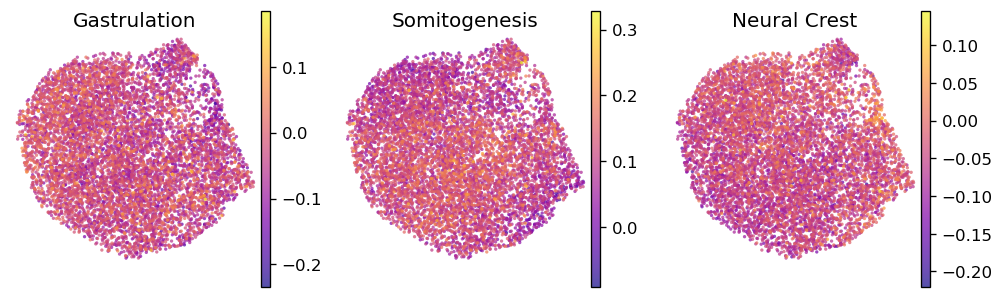

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.05
fig, axes = plt.subplots(1, 3, figsize=(8.4,2.6))
for ax,(m,title) in zip(axes, modules.items()):
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=16, colorbar_loc='right',
               frameon=False, show=False, ax=ax, title=title)
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py); ax.set_aspect('equal')
fig.tight_layout()

### Per-module signature figures + colorbars (deliverable)
House style adapted to the round-blob geometry: square panels (equal aspect),
`size=16`, plasma, pseudotime left→right, one colorbar PDF per module with
data-driven ticks. Raw (unsmoothed) scores are shown, per the deliverable
convention.

saved Gast_signature.pdf + colorbar
saved pSom_signature.pdf + colorbar
saved Crest_signature.pdf + colorbar


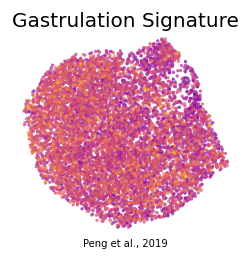

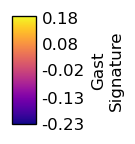

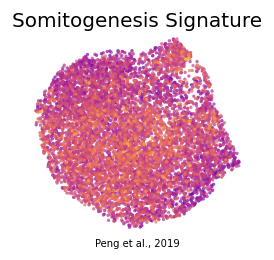

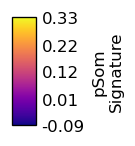

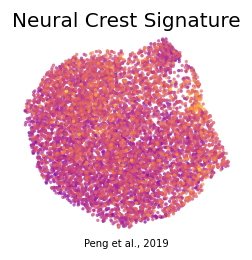

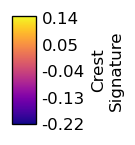

In [ ]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.05
titles = {'Gast':'Gastrulation Signature','pSom':'Somitogenesis Signature','Crest':'Neural Crest Signature'}
for m in ['Gast','pSom','Crest']:
    fig, ax = plt.subplots(figsize=(2.5,2.1))
    sc.pl.umap(plot, color=m, cmap='plasma', alpha=.7, size=16, colorbar_loc=None,
               frameon=False, show=False, ax=ax, title=titles[m])
    ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py); ax.set_aspect('equal')
    ax.text(.5,-.08,'Peng et al., 2019', ha='center', transform=ax.transAxes, size=6)
    fig.savefig(os.path.join(pth_fig, f'{m}_signature.pdf'), bbox_inches='tight')
    lo, hi = float(adata.obs[m].min()), float(adata.obs[m].max())
    ticks = np.round(np.linspace(lo, hi, 5), 2)
    fcb = plt.figure(figsize=(.66,1)); cax = fcb.add_axes([.35,.05,.3,.9])
    cb = plt.colorbar(ax.collections[0], cax=cax); cb.ax.tick_params(which='both', size=0)
    cb.set_label(f'{m}\nSignature'); cb.set_ticks(ticks, labels=ticks); cb.solids.set_alpha(1)
    fcb.savefig(os.path.join(pth_cb, f'{m}_colorbar.pdf'), bbox_inches='tight')
    print('saved', f'{m}_signature.pdf', '+ colorbar')

### Save signatures data

In [ ]:
adata.write(os.path.join(pth_out, 'signatures.h5ad'))
print('saved signatures.h5ad', adata.shape)

saved signatures.h5ad (7945, 17154)
